# EV Battery Failure: Exploratory Data Analysis
## Goal
Inspect data quality, class balance, telemetry distributions, and relationships with battery failure.
The target is `battery_failure` (0 = healthy, 1 = failure).

## Setup
Select a Python 3.11+ Jupyter kernel with the project requirements installed.
From the project root, install with `python -m pip install -e .` and
`python -m pip install notebook ipykernel`. Then run the cells in order.

### Key assumptions
Rows have unique vehicle and battery identifiers. Data are simulated, with no timestamp or
prediction horizon. Global profiling uses all rows; all target-conditioned exploration uses
only the reproducible 60% training split. Calibration, threshold, and test rows stay outside
feature decisions. Missing values are profiled here and imputed inside training pipelines.


In [1]:
from pathlib import Path
import sys

# Works when Jupyter starts in the data folder, project root, or parent folder.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "Ev_Battery_ML_Project"]
PROJECT_ROOT = next((p for p in candidates if (p / "src" / "evbattery").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the EV battery project folder.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from evbattery.config import TARGET
from evbattery.data import load_dataset, split_data, make_features

DATA_PATH = PROJECT_ROOT / "data" / "ev_battery.csv"
BENCHMARK_ONLY = not DATA_PATH.is_file()
if BENCHMARK_ONLY:
    DATA_PATH = PROJECT_ROOT / "data" / "synthetic_benchmark.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError("Place ev_battery.csv in the project's data folder.")
RUN_NAME = "benchmark" if BENCHMARK_ONLY else "dataset"
display(Markdown(f"**Input:** `{DATA_PATH.name}`. " + (
    "**Benchmark demonstration only: these outputs are not results for the main dataset.**"
    if BENCHMARK_ONLY else "Simulated dataset; results do not establish real-vehicle forecasting.")))
df = load_dataset(DATA_PATH)
splits = split_data(df)
train = splits.train
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns")
get_ipython().run_line_magic("matplotlib", "inline")


**Input:** `synthetic_benchmark.csv`. **Benchmark demonstration only: these outputs are not results for the main dataset.**

Loaded 1,000 rows and 70 columns


## 1. Preview and schema

In [2]:
display(df.head())
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "unique_values": df.nunique()}))

,vehicle_id,battery_serial,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,...,abnormal_voltage_events,maintenance_score,thermal_runaway_risk,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,veh_00000,bat_00000,Hyundai,Leaf,Hatchback,2020.0,CATL,NMC,68.602214,FWD,...,50.171967,14.315153,84.574132,38.276028,70.023519,37.346093,96.081747,30.042866,64.361976,0
1,veh_00001,bat_00001,BYD,Model 3,Sedan,2023.0,CATL,LFP,76.970269,AWD,...,97.369324,83.615473,76.024602,91.961706,98.011003,52.633792,61.553406,75.101659,35.188591,0
2,veh_00002,bat_00002,Hyundai,Model 3,SUV,2019.0,LG,LTO,72.788004,FWD,...,13.938951,35.689013,87.901351,61.108121,39.321008,53.553726,59.898186,30.085640,62.752267,0
3,veh_00003,bat_00003,Hyundai,Leaf,Sedan,2022.0,CATL,NMC,94.277900,FWD,...,11.323174,37.419456,95.297876,29.619844,24.501244,59.352605,13.157637,49.402769,47.641221,0
4,veh_00004,bat_00004,Tesla,Seal,SUV,2024.0,LG,LFP,83.959506,RWD,...,92.339984,48.997936,60.775820,86.595381,15.323386,89.045609,42.649367,69.208042,34.686328,0


,dtype,unique_values
vehicle_id,object,1000
battery_serial,object,1000
vehicle_brand,object,4
vehicle_model,object,4
vehicle_type,object,3
...,...,...
thermal_health_score,float64,1000
charging_quality_score,float64,1000
driving_stress_score,float64,1000
predicted_remaining_life_cycles,float64,1000


## 2. Data quality and feature decisions
Reuse the project's existing audit functions. Flagged plausibility rules require investigation; they do not automatically justify deleting rows.

In [3]:
from evbattery.eda import (
    overview, column_dictionary, plausibility_checks, class_comparison,
    categorical_failure_rates, missingness_vs_target,
)
display(pd.Series(overview(df), name="value").to_frame())
dictionary = column_dictionary(df)
display(dictionary)
display(df.describe().T.round(3))
checks = plausibility_checks(df)
display(checks)
get_ipython().run_line_magic("matplotlib", "inline")


,value
n_rows,1000
n_columns,70
n_numeric_columns,60
n_text_columns,10
healthy,669
failures,331
failure_prevalence,0.331
all_healthy_baseline_accuracy,0.669
missing_cells,0
missing_percent_of_table,0.0


,column,group,meaning,type,missing_percent,n_unique,min,median,max,decision,reason
0,vehicle_id,identifier,Unique vehicle code,categorical/text,0.0,1000,NaN,NaN,NaN,drop_id,Unique per row; carries no physics and lets a ...
1,battery_serial,identifier,Unique battery serial number,categorical/text,0.0,1000,NaN,NaN,NaN,drop_id,Unique per row; carries no physics and lets a ...
2,vehicle_brand,vehicle,Manufacturer brand (20 brands),categorical/text,0.0,4,NaN,NaN,NaN,keep,Raw telemetry/specification plausibly availabl...
3,vehicle_model,vehicle,Model name (42 models),categorical/text,0.0,4,NaN,NaN,NaN,keep,Raw telemetry/specification plausibly availabl...
4,vehicle_type,vehicle,"Body type, e.g. SUV, Van",categorical/text,0.0,3,NaN,NaN,NaN,keep,Raw telemetry/specification plausibly availabl...
...,...,...,...,...,...,...,...,...,...,...,...
65,thermal_health_score,composite_score,Precomputed thermal health score,numeric,0.0,1000,10.170,54.737,99.848,exclude_suspect,Precomputed score with unknown formula/timing;...
66,charging_quality_score,composite_score,Precomputed charging quality score,numeric,0.0,1000,10.268,56.437,99.837,exclude_suspect,Precomputed score with unknown formula/timing;...
67,driving_stress_score,composite_score,Precomputed driving stress score,numeric,0.0,1000,10.020,56.264,99.921,exclude_suspect,Precomputed score with unknown formula/timing;...
68,predicted_remaining_life_cycles,composite_score,Model-predicted remaining life (cycles),numeric,0.0,1000,10.123,55.556,99.747,exclude_suspect,Precomputed score with unknown formula/timing;...


,count,mean,std,min,25%,50%,75%,max
manufacturing_year,1000.0,2020.513,2.646,2016.000,2018.000,2021.000,2023.000,2025.000
battery_capacity_kwh,1000.0,70.507,16.775,40.249,56.663,70.357,84.537,99.966
odometer_km,1000.0,79524.884,42594.076,5232.932,42622.517,81499.270,116821.591,149980.224
vehicle_age_years,1000.0,5.477,2.596,1.005,3.198,5.478,7.704,9.999
cycle_count,1000.0,1042.986,531.787,103.000,604.750,1033.000,1494.750,1996.000
battery_health_percent,1000.0,80.194,11.621,60.006,69.476,80.442,90.521,99.870
state_of_charge,1000.0,54.521,25.838,10.018,32.011,53.515,76.604,99.974
depth_of_discharge,1000.0,56.747,25.788,10.119,34.926,58.597,79.332,99.921
state_of_health,1000.0,80.166,11.632,58.393,69.548,80.558,90.363,101.109
cell_voltage_avg,1000.0,55.687,26.406,10.005,32.884,55.056,78.726,99.936


,status,check,rows_flagged,percent_of_rows,why_it_matters
0,FLAG,cell_temperature_avg > cell_temperature_max,104,10.4,average can never exceed maximum
1,PASS,ambient: maximum_temperature < minimum_tempera...,0,0.0,max must be >= min
2,FLAG,"ambient average outside [min, max]",207,20.7,average must lie between min and max
3,PASS,fast_charge_ratio outside 0-1,0,0.0,ratio must be a share
4,PASS,slow_charge_ratio outside 0-1,0,0.0,ratio must be a share
5,FLAG,overnight_charging_ratio outside 0-1,1000,100.0,ratio must be a share
6,FLAG,home_charging_ratio outside 0-1,1000,100.0,ratio must be a share
7,FLAG,highway_driving_ratio outside 0-1,1000,100.0,ratio must be a share
8,FLAG,city_driving_ratio outside 0-1,1000,100.0,ratio must be a share
9,PASS,battery_health_percent outside 0-100,0,0.0,percentage


## 3. Missing values

,missing_percent
vehicle_id,0.0
battery_serial,0.0
vehicle_brand,0.0
vehicle_model,0.0
vehicle_type,0.0
...,...
thermal_health_score,0.0
charging_quality_score,0.0
driving_stress_score,0.0
predicted_remaining_life_cycles,0.0


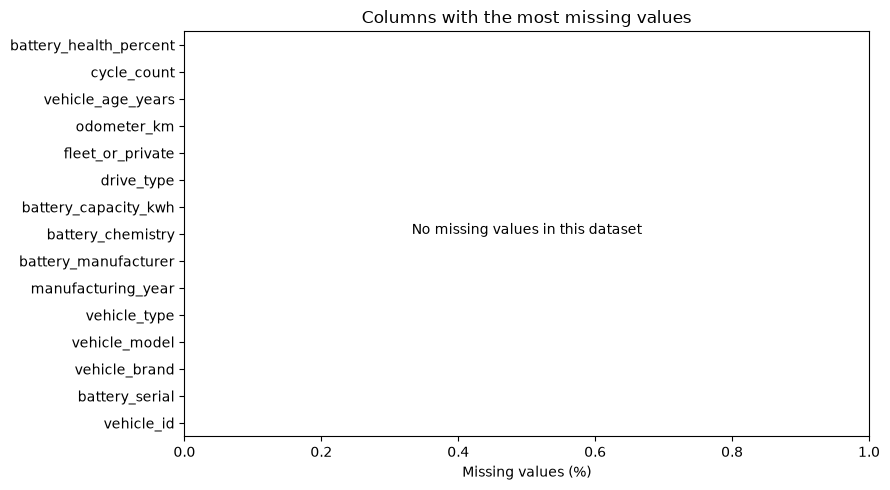

In [4]:
missing = df.isna().mean().mul(100).sort_values(ascending=False)
display(missing.rename("missing_percent").to_frame())
fig, ax = plt.subplots(figsize=(9, 5))
missing.head(15).sort_values().plot.barh(ax=ax, color="steelblue")
ax.set(xlabel="Missing values (%)", title="Columns with the most missing values")
ax.set_xlim(0, max(1, float(missing.max()) * 1.15))
if not missing.any():
    ax.text(0.5, 0.5, "No missing values in this dataset", transform=ax.transAxes, ha="center")
plt.tight_layout()
plt.show()

## 4. Target balance
Class counts describe the dataset. Accuracy alone can be misleading when failures are uncommon.

,rows,percent
battery_failure,,
0,669,66.9
1,331,33.1


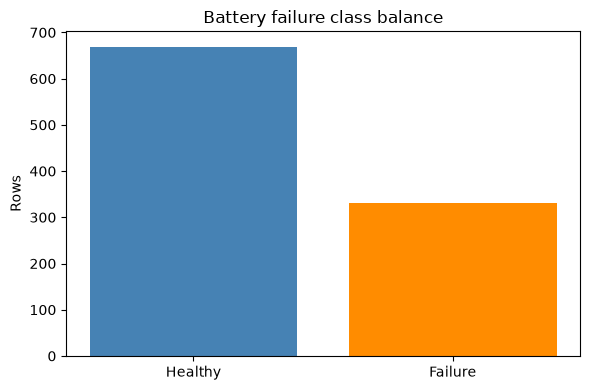

In [5]:
counts = df[TARGET].value_counts().reindex([0, 1], fill_value=0)
display(pd.DataFrame({"rows": counts, "percent": counts / len(df) * 100}))
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Healthy", "Failure"], counts, color=["steelblue", "darkorange"])
ax.set(ylabel="Rows", title="Battery failure class balance")
plt.tight_layout()
plt.show()

## 5. Numeric distributions by class (training only)

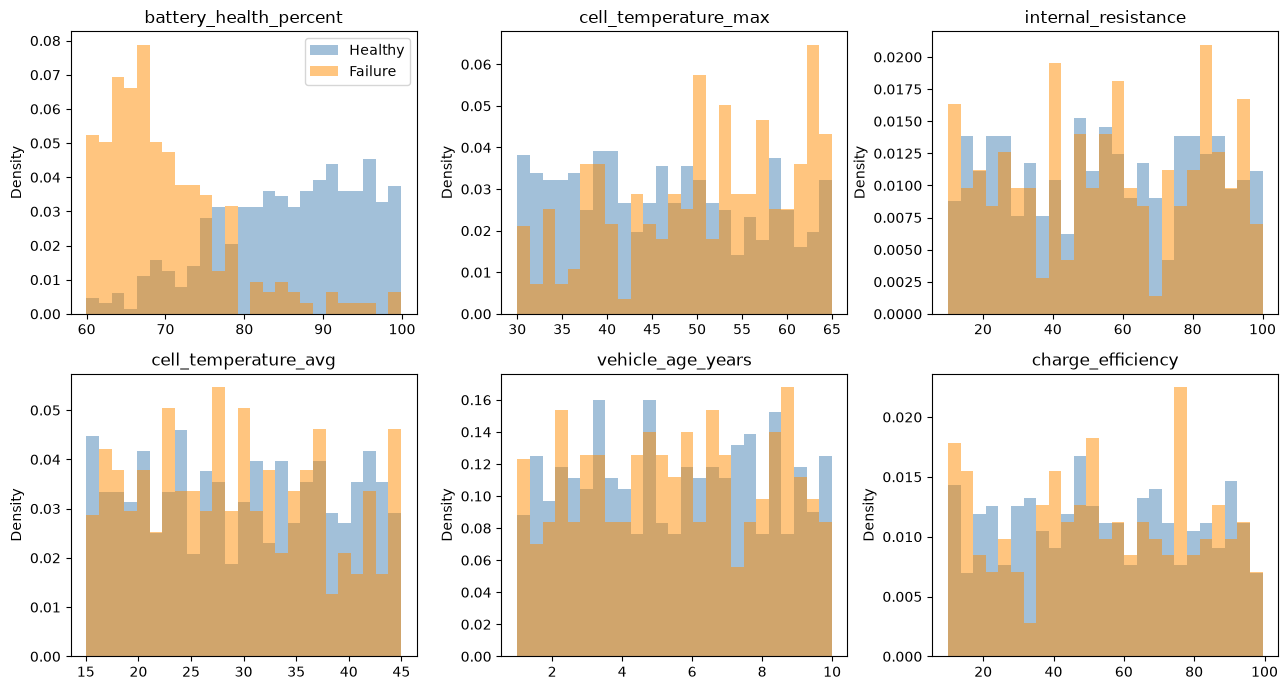

,feature,healthy_median,failure_median,healthy_mean,failure_mean,standardised_mean_difference,is_suspect_score
5,battery_health_percent,86.786,67.839,85.548,69.850,-1.840,False
18,capacity_loss_percent,13.214,32.161,14.452,30.150,1.840,False
8,state_of_health,86.495,68.062,85.547,69.804,-1.839,False
17,remaining_capacity,61.032,48.727,61.694,48.600,-0.903,False
13,cell_temperature_max,45.872,51.631,46.145,50.593,0.446,False
29,average_trip_distance,53.648,61.274,53.956,59.531,0.214,False
19,charging_cycles_last_month,60.493,51.534,58.734,53.665,-0.198,False
55,thermal_health_score,56.353,49.757,56.635,52.697,-0.155,True
24,overnight_charging_ratio,57.036,51.629,56.011,52.137,-0.152,False
6,state_of_charge,50.920,57.056,53.089,56.958,0.150,False


In [6]:
from evbattery.eda import KEY_NUMERIC
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, feature in zip(axes.flat, KEY_NUMERIC):
    values = train[feature].dropna()
    _, bins = pd.cut(values, bins=25, retbins=True, duplicates="drop")
    for label, name, color in [(0, "Healthy", "steelblue"), (1, "Failure", "darkorange")]:
        ax.hist(train.loc[train[TARGET].eq(label), feature].dropna(),
                bins=bins, density=True, alpha=0.5, label=name, color=color)
    ax.set(title=feature, ylabel="Density")
axes.flat[0].legend()
plt.tight_layout()
plt.show()
display(class_comparison(train))

## 6. Numeric relationships (training only)
Correlation describes association, not causation or future predictive lead time.

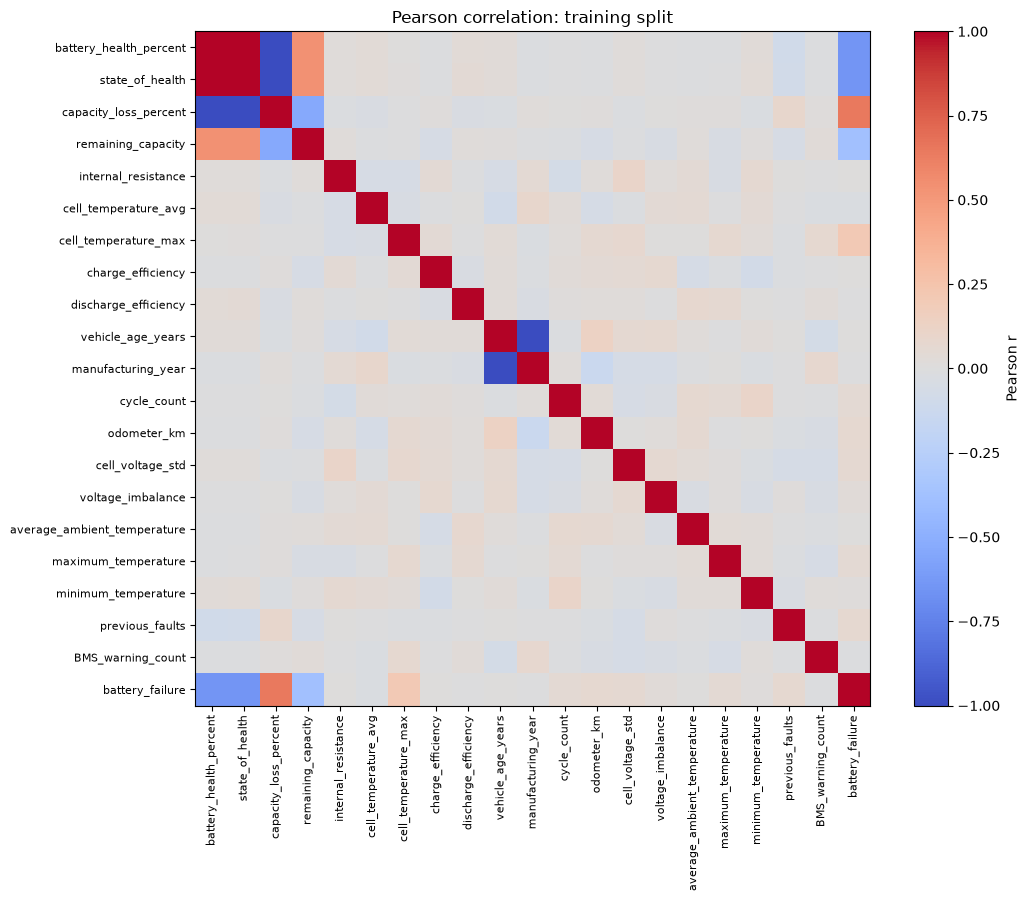

In [7]:
from evbattery.eda import HEATMAP_FEATURES
columns = [c for c in HEATMAP_FEATURES if c in train]
corr = train[columns].corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(columns)), columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(columns)), columns, fontsize=8)
ax.set_title("Pearson correlation: training split")
fig.colorbar(im, ax=ax, label="Pearson r")
plt.tight_layout()
plt.show()

## 7. Categorical patterns and missingness (training only)

,column,level,rows,failures,failure_rate
0,vehicle_brand,BYD,164,59,0.3598
1,vehicle_brand,Hyundai,166,56,0.3373
2,vehicle_brand,Nissan,128,43,0.3359
3,vehicle_brand,Tesla,142,41,0.2887
4,vehicle_model,Ioniq,147,46,0.3129
5,vehicle_model,Leaf,151,53,0.3510
6,vehicle_model,Model 3,165,56,0.3394
7,vehicle_model,Seal,137,44,0.3212
8,vehicle_type,Hatchback,211,78,0.3697
9,vehicle_type,SUV,201,59,0.2935


No missing values in the training split; missingness comparison is unnecessary.


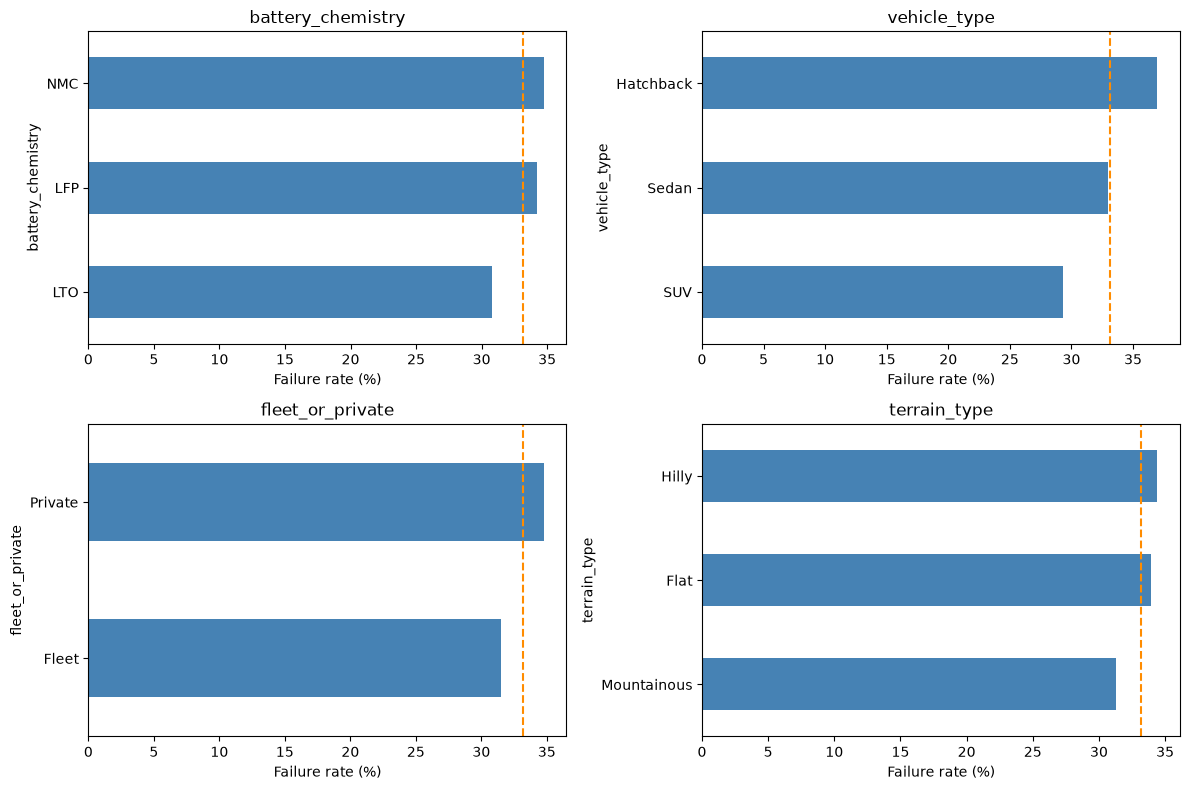

In [8]:
from evbattery.eda import CATEGORICAL_PLOTS
display(categorical_failure_rates(train))
if train.isna().any().any():
    display(missingness_vs_target(train))
else:
    print("No missing values in the training split; missingness comparison is unnecessary.")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, CATEGORICAL_PLOTS):
    rates = train.groupby(train[feature].fillna("(missing)"))[TARGET].mean().mul(100).sort_values()
    rates.plot.barh(ax=ax, color="steelblue")
    ax.axvline(train[TARGET].mean() * 100, color="darkorange", linestyle="--")
    ax.set(title=feature, xlabel="Failure rate (%)")
plt.tight_layout()
plt.show()

## 8. Save the audit tables

In [9]:
OUTDIR = PROJECT_ROOT / "artifacts" / "notebooks" / RUN_NAME / "eda"
OUTDIR.mkdir(parents=True, exist_ok=True)
dictionary.to_csv(OUTDIR / "column_dictionary.csv", index=False)
checks.to_csv(OUTDIR / "plausibility_checks.csv", index=False)
missing.to_csv(OUTDIR / "missing_by_column.csv", header=["missing_percent"])
class_comparison(train).to_csv(OUTDIR / "class_comparison_train.csv", index=False)
print(f"Tables saved to {OUTDIR}")
display(Markdown(
    f"### Observed checks\n"
    f"- Input: `{DATA_PATH.name}`; {len(df):,} rows.\n"
    f"- Failure prevalence: {df[TARGET].mean():.2%}.\n"
    f"- Missing cells: {int(df.isna().sum().sum()):,}.\n"
    f"- Plausibility rules flagged: {int(checks['status'].eq('FLAG').sum())}."
))

Tables saved to D:\5 th Sem project\Machine Learing Group Project\Ev_Battery_ML_Project\artifacts\notebooks\benchmark\eda


### Observed checks
- Input: `synthetic_benchmark.csv`; 1,000 rows.
- Failure prevalence: 33.10%.
- Missing cells: 0.
- Plausibility rules flagged: 13.

## Next steps
Open `02_Model_Training.ipynb`. Its preprocessing drops identifiers, suspect composite scores, and configured redundant columns; imputers and encoders fit inside each training fold. Benchmark findings must not be reported as main-dataset findings.